# Exploratory Data Analysis (EDA)

## Project: Credit Risk Analytics — Predicting Credit Card Default

### 2.1 Introduction

Exploratory Data Analysis (EDA) is performed to understand the distributions, patterns, relationships and trends within the dataset.

This phase focuses on identifying factors associated with credit card default and understanding how customer characteristics and repayment behaviour relate to the target variable.

### Objectives

1. Examine the distribution of the target variable.
2. Analyse demographic characteristics of clients.
3. Investigate the relationship between credit limits and default.
4. Explore repayment history and its association with default.
5. Analyse billing and payment amount patterns.
6. Identify relationships between numerical and categorical variables.
7. Develop meaningful insights to support subsequent machine learning.

### Dataset Overview

- Total observations: 30,000
- Total variables: 25
- Predictor variables: 23
- Identifier: ID
- Target variable: default payment next month

The analysis will use visualizations and statistical summaries to identify meaningful patterns. No observations will be removed solely because they appear unusual.

### 2.2 Import Libraries and Prepare Dataset

The required Python libraries will be imported for data manipulation, statistical analysis and visualization.

The structurally corrected dataset will be loaded from the original Excel file. The header correction and numeric conversion will be repeated to ensure that this notebook can run independently of the previous notebook.

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Set visualization style
sns.set_theme(style="whitegrid")

# Load the original dataset
DATA_PATH = Path("../data/default of credit card clients.xls")
df = pd.read_excel(DATA_PATH)

# Correct column headers
df.columns = df.iloc[0].astype(str).str.strip()
df = df.iloc[1:].reset_index(drop=True)

# Convert columns to numeric
df = df.apply(pd.to_numeric)

# Display dataset dimensions
print("Dataset Shape:", df.shape)

Dataset Shape: (30000, 25)


### 2.3 Target Variable Distribution

The target variable, `default payment next month`, represents whether a client defaults on their credit card payment in the following month.

The dataset contains two classes:

- 0: No Default
- 1: Default

We will examine the frequency and percentage of each class to understand the target distribution and class imbalance.

This analysis will establish a baseline for interpreting subsequent findings.

In [5]:
# Calculate target class frequencies
target_counts = df["default payment next month"].value_counts().sort_index()

# Calculate target class percentages
target_percentages = (
    df["default payment next month"]
    .value_counts(normalize=True)
    .sort_index() * 100
).round(2)

# Display results
target_summary = pd.DataFrame({
    "Number of Clients": target_counts,
    "Percentage": target_percentages
})

print(target_summary)

                            Number of Clients  Percentage
default payment next month                               
0                                       23364       77.88
1                                        6636       22.12


### 2.4 Target Distribution Visualization

A bar chart will be used to visualize the distribution of clients across the two target classes.

The visualization will help compare the number of non-default and default clients and highlight the class imbalance present in the dataset.

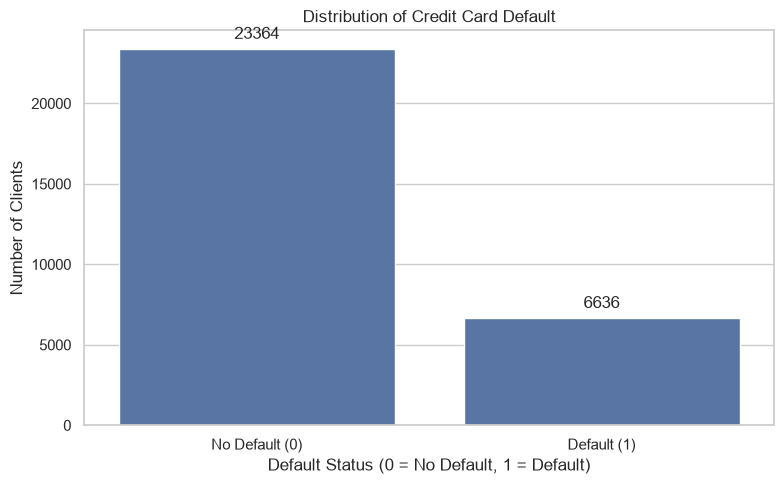

In [6]:
# Calculate target class frequencies
target_counts = df["default payment next month"].value_counts().sort_index()

# Create bar chart
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    x=target_counts.index,
    y=target_counts.values
)

# Add count labels
for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=5)

plt.title("Distribution of Credit Card Default")
plt.xlabel("Default Status (0 = No Default, 1 = Default)")
plt.ylabel("Number of Clients")
plt.xticks([0, 1], ["No Default (0)", "Default (1)"])

plt.tight_layout()
plt.show()

### 2.5 Target Distribution Insights

The target variable visualization confirms the class imbalance in the dataset.

Key observations:

- 23,364 clients (77.88%) belong to the non-default category.
- 6,636 clients (22.12%) belong to the default category.
- The non-default class is approximately 3.52 times larger than the default class.

This imbalance indicates that accuracy alone may be misleading when evaluating classification models.

Therefore, precision, recall, F1-score and ROC-AUC will be considered during model evaluation, with particular attention to identifying default cases.

### 2.6 Gender Analysis and Credit Default

This section examines the distribution of clients by gender and investigates whether default rates differ between male and female clients.

The analysis will include:
- Number of male and female clients.
- Default and non-default counts by gender.
- Default percentage within each gender category.

The objective is to identify patterns in the dataset rather than assume that gender causes credit default.

In [7]:
# Calculate gender distribution by default status
gender_default = pd.crosstab(
    df["SEX"],
    df["default payment next month"]
)

# Calculate default percentage within each gender
gender_default_rate = (
    df.groupby("SEX")["default payment next month"]
    .mean() * 100
).round(2)

# Display results
print("Gender Distribution by Default Status:")
print(gender_default)

print("\nDefault Rate by Gender (%):")
print(gender_default_rate)

Gender Distribution by Default Status:
default payment next month      0     1
SEX                                    
1                            9015  2873
2                           14349  3763

Default Rate by Gender (%):
SEX
1    24.17
2    20.78
Name: default payment next month, dtype: float64


### 2.7 Gender Analysis Findings

The relationship between gender and credit card default was examined.

Key observations:

- Male clients have a default rate of 24.17%.
- Female clients have a default rate of 20.78%.
- The difference between the two observed default rates is 3.39 percentage points.
- Female clients account for a larger proportion of the dataset.

The results indicate a difference in observed default rates across gender categories. However, this association does not establish a causal relationship.

Further analysis will examine other demographic and financial variables.

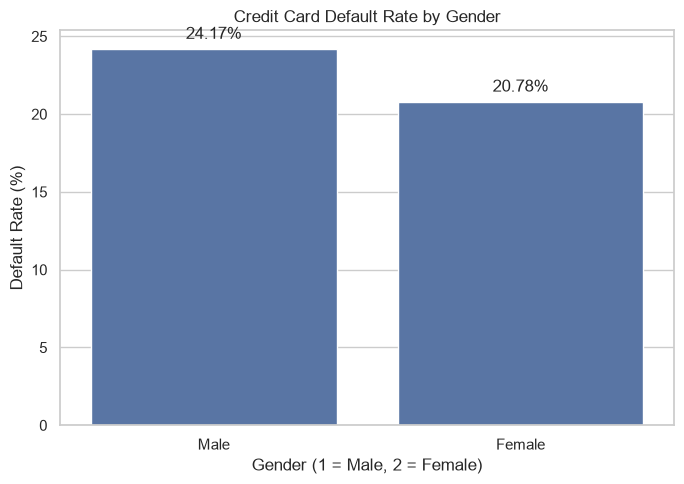

In [8]:
# Calculate default rate by gender
gender_default_rate = (
    df.groupby("SEX")["default payment next month"]
    .mean() * 100
)

# Create bar chart
plt.figure(figsize=(7, 5))

ax = sns.barplot(
    x=gender_default_rate.index,
    y=gender_default_rate.values
)

# Add percentage labels
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=5)

plt.title("Credit Card Default Rate by Gender")
plt.xlabel("Gender (1 = Male, 2 = Female)")
plt.ylabel("Default Rate (%)")
plt.xticks([0, 1], ["Male", "Female"])

plt.tight_layout()
plt.show()

### 2.8 Gender Visualization Insights

The visualization highlights the difference in credit card default rates across gender categories.

Key observations:

- Male clients exhibit a higher default rate of 24.17%.
- Female clients exhibit a default rate of 20.78%.
- The difference between the two categories is 3.39 percentage points.

The visualization supports the findings from the statistical analysis. Gender alone is insufficient to explain default behaviour, so additional demographic and financial characteristics will be investigated.

### 2.9 Age Distribution Analysis

This section examines the age distribution of clients to understand the demographic composition of the dataset.

The analysis will investigate:

- The distribution of client ages.
- The average and median client age.
- The age groups containing the largest number of clients.
- Differences in default rates across age groups.

Age groups will be created to make demographic comparisons easier to interpret.

Age Statistics:
count    30000.000000
mean        35.485500
std          9.217904
min         21.000000
25%         28.000000
50%         34.000000
75%         41.000000
max         79.000000
Name: AGE, dtype: float64


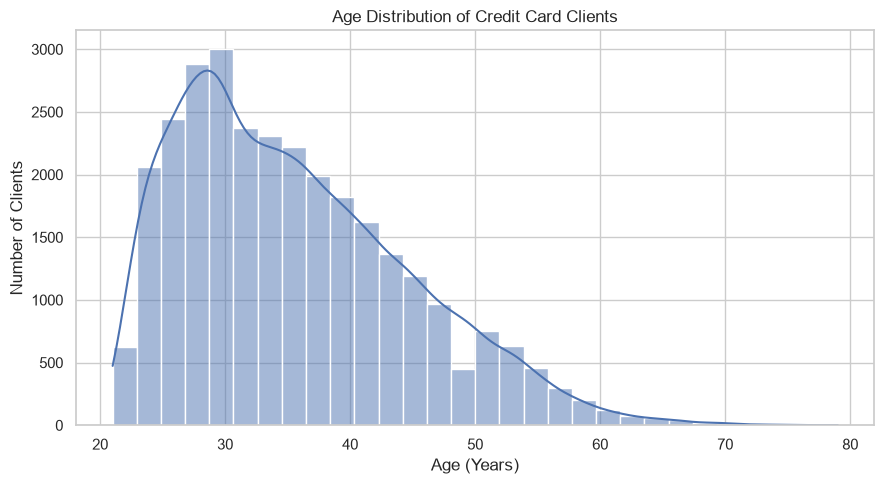

In [10]:
# Calculate age statistics
print("Age Statistics:")
print(df["AGE"].describe())

# Create age distribution histogram
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="AGE",
    bins=30,
    kde=True
)

plt.title("Age Distribution of Credit Card Clients")
plt.xlabel("Age (Years)")
plt.ylabel("Number of Clients")

plt.tight_layout()
plt.show()

### 2.10 Age Distribution Insights

The age distribution of credit card clients was examined using descriptive statistics and a histogram.

Key observations:

- The average client age is approximately 35.49 years.
- The median age is 34 years.
- Client ages range from 21 to 79 years.
- Most clients are concentrated between approximately 25 and 40 years.
- The mean being higher than the median suggests a positively skewed age distribution.
- The number of clients decreases considerably in older age groups.

The findings indicate that the dataset contains a relatively young adult client population, with fewer observations among older age groups.

### 2.11 Age Group Analysis and Credit Default

To investigate how default behaviour varies across different age ranges, clients will be divided into age groups.

The analysis will examine:

- Number of clients in each age group.
- Number of default and non-default clients.
- Default rate within each age group.

Age grouping will make it easier to compare default patterns across different demographic segments.

In [11]:
# Define age group boundaries and labels
age_bins = [20, 25, 30, 35, 40, 50, 60, 80]
age_labels = [
    "21-25", "26-30", "31-35",
    "36-40", "41-50", "51-60", "61-79"
]

# Create age groups
df["AGE_GROUP"] = pd.cut(
    df["AGE"],
    bins=age_bins,
    labels=age_labels,
    include_lowest=True
)

# Calculate client distribution and default rates
age_default_summary = df.groupby(
    "AGE_GROUP",
    observed=False
).agg(
    Total_Clients=("default payment next month", "count"),
    Default_Clients=("default payment next month", "sum"),
    Default_Rate=("default payment next month", "mean")
)

# Convert default rate into percentage
age_default_summary["Default_Rate"] *= 100
age_default_summary["Default_Rate"] = (
    age_default_summary["Default_Rate"].round(2)
)

print(age_default_summary)

           Total_Clients  Default_Clients  Default_Rate
AGE_GROUP                                              
21-25               3871             1032         26.66
26-30               7142             1439         20.15
31-35               5796             1126         19.43
36-40               4917             1063         21.62
41-50               6005             1399         23.30
51-60               1997              504         25.24
61-79                272               73         26.84


### 2.12 Age Group Analysis Findings

Clients were divided into seven age groups to examine differences in credit card default rates.

Key observations:

- The 61–79 age group has the highest default rate of 26.84%, based on 272 clients.
- The 21–25 age group has a default rate of 26.66%.
- The 31–35 age group has the lowest default rate of 19.43%.
- Default rates generally increase again among older age groups after reaching their lowest level in the 31–35 group.
- The 26–30 age group contains the largest number of clients, with 7,142 observations.

The results suggest a non-linear association between age and default behaviour.

The relatively small sample size of the 61–79 age group should be considered when interpreting its default rate.

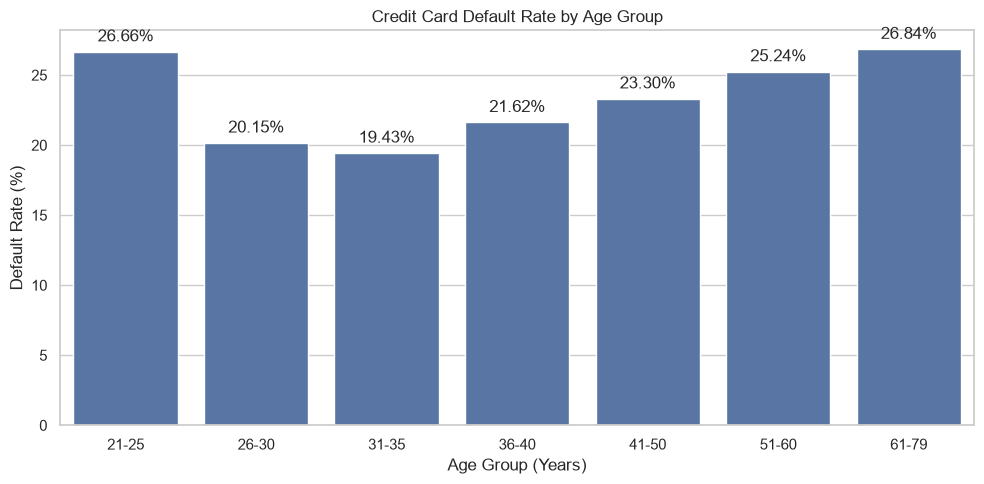

In [12]:
# Create figure
plt.figure(figsize=(10, 5))

# Plot default rates
ax = sns.barplot(
    data=age_default_summary.reset_index(),
    x="AGE_GROUP",
    y="Default_Rate"
)

# Add percentage labels
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=5)

plt.title("Credit Card Default Rate by Age Group")
plt.xlabel("Age Group (Years)")
plt.ylabel("Default Rate (%)")

plt.tight_layout()
plt.show()

### 2.13 Age Group Visualization Insights

The visualization highlights differences in credit card default rates across age groups.

Key observations:

- The 21–25 age group has a default rate of 26.66%.
- The 31–35 age group has the lowest default rate of 19.43%.
- Default rates generally increase across older age groups after the 31–35 category.
- The 61–79 age group has the highest observed default rate of 26.84%, although it contains relatively few clients.

The results indicate a non-linear relationship between age and default behaviour. Age may provide useful information for credit risk analysis, but it should be considered alongside other financial and repayment characteristics.

### 2.14 Credit Limit Distribution Analysis

The LIMIT_BAL variable represents the assigned credit limit for each client.

This section examines the distribution of credit limits to understand:

- The range of credit limits assigned to clients.
- The most common credit limit ranges.
- The average and median credit limits.
- Whether credit limits are distributed symmetrically or skewed.

This analysis will provide a foundation for investigating the relationship between credit limits and default behaviour.

Credit Limit Statistics:
count      30000.000000
mean      167484.322667
std       129747.661567
min        10000.000000
25%        50000.000000
50%       140000.000000
75%       240000.000000
max      1000000.000000
Name: LIMIT_BAL, dtype: float64


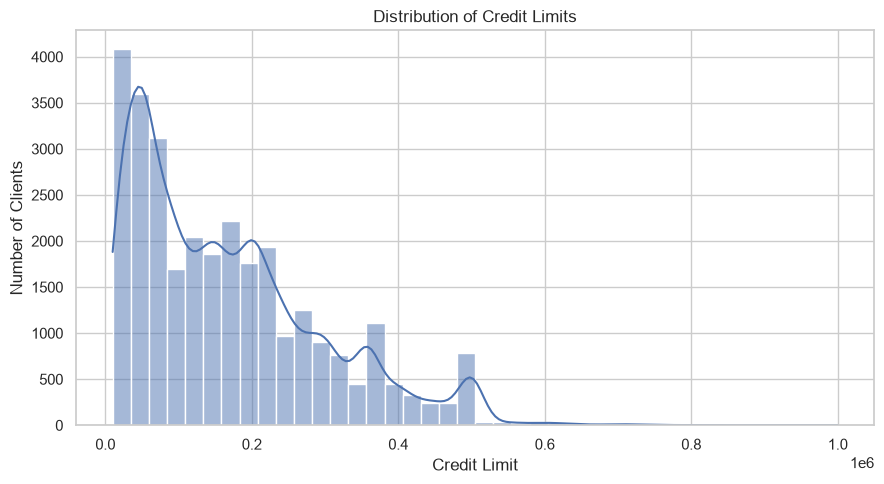

In [13]:
# Calculate credit limit statistics
print("Credit Limit Statistics:")
print(df["LIMIT_BAL"].describe())

# Plot credit limit distribution
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="LIMIT_BAL",
    bins=40,
    kde=True
)

plt.title("Distribution of Credit Limits")
plt.xlabel("Credit Limit")
plt.ylabel("Number of Clients")

plt.tight_layout()
plt.show()

### 2.15 Credit Limit Distribution Insights

The credit limit distribution was examined using descriptive statistics and a histogram.

Key observations:

- The average credit limit is approximately 167,484.
- The median credit limit is 140,000.
- Credit limits range from 10,000 to 1,000,000.
- The mean being higher than the median indicates a positively skewed distribution.
- Most clients have credit limits below 200,000.
- Higher credit limits are comparatively less frequent.

The distribution also contains multiple peaks, suggesting that credit limits are assigned at specific discrete values rather than uniformly across the range.

### 2.16 Credit Limit and Credit Default Analysis

This section investigates the relationship between assigned credit limits and credit card default.

Clients will be divided into credit limit groups to examine:

- Number of clients in each credit limit category.
- Number of default cases within each category.
- Default rate for each credit limit category.

This analysis will help identify whether default rates vary across different credit exposure levels.

In [14]:
# Define credit limit ranges
credit_bins = [0, 50000, 100000, 200000, 300000, 500000, 1000001]

credit_labels = [
    "10K-50K",
    "50K-100K",
    "100K-200K",
    "200K-300K",
    "300K-500K",
    "500K-1M"
]

# Create credit limit groups
df["CREDIT_LIMIT_GROUP"] = pd.cut(
    df["LIMIT_BAL"],
    bins=credit_bins,
    labels=credit_labels,
    include_lowest=True
)

# Calculate default statistics
credit_default_summary = df.groupby(
    "CREDIT_LIMIT_GROUP",
    observed=False
).agg(
    Total_Clients=("default payment next month", "count"),
    Default_Clients=("default payment next month", "sum"),
    Default_Rate=("default payment next month", "mean")
)

# Convert default rate into percentage
credit_default_summary["Default_Rate"] = (
    credit_default_summary["Default_Rate"] * 100
).round(2)

print(credit_default_summary)

                    Total_Clients  Default_Clients  Default_Rate
CREDIT_LIMIT_GROUP                                              
10K-50K                      7676             2440         31.79
50K-100K                     4822             1244         25.80
100K-200K                    7880             1535         19.48
200K-300K                    5059              812         16.05
300K-500K                    4357              582         13.36
500K-1M                       206               23         11.17


### 2.17 Credit Limit and Default Analysis Findings

The relationship between assigned credit limits and credit card default was examined by dividing clients into six credit limit categories.

Key observations:

- The 10K–50K category has the highest default rate of 31.79%.
- The 500K–1M category has the lowest default rate of 11.17%.
- Default rates decrease consistently across the credit limit categories.
- The 100K–200K category contains the largest number of clients, with 7,880 observations.
- The highest credit limit category contains only 206 clients, so its default rate should be interpreted cautiously.

The findings indicate an inverse association between credit limit categories and observed default rates.

Credit limit may provide useful information for credit risk prediction, although the observed relationship does not establish causation.

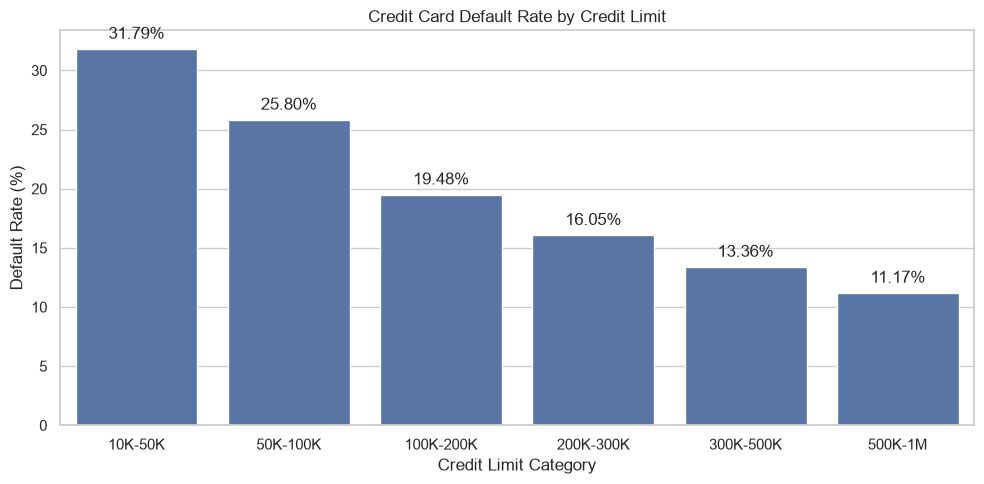

In [15]:
# Create figure
plt.figure(figsize=(10, 5))

# Plot default rates
ax = sns.barplot(
    data=credit_default_summary.reset_index(),
    x="CREDIT_LIMIT_GROUP",
    y="Default_Rate"
)

# Add percentage labels
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=5)

plt.title("Credit Card Default Rate by Credit Limit")
plt.xlabel("Credit Limit Category")
plt.ylabel("Default Rate (%)")

plt.tight_layout()
plt.show()

### 2.18 Credit Limit Visualization Insights

The visualization highlights the relationship between credit limit categories and observed credit card default rates.

Key observations:

- The 10K–50K category has the highest default rate of 31.79%.
- The 500K–1M category has the lowest default rate of 11.17%.
- Default rates decline consistently across the six credit limit categories.
- The difference between the highest and lowest category default rates is 20.62 percentage points.

The results suggest that credit limit is an informative variable for understanding default patterns. However, this association does not establish a causal relationship.

### 2.19 Education Level and Credit Default Analysis

This section investigates the relationship between clients' education levels and credit card default.

The analysis will examine:

- Number of clients in each education category.
- Number of default and non-default clients.
- Default rate within each education category.

The dataset contains the following education codes:

- 0: Undocumented category
- 1: Graduate school
- 2: University
- 3: High school
- 4: Others
- 5 and 6: Unknown categories

These categories will be retained separately during the initial analysis.

In [16]:
# Calculate education distribution by default status
education_default = pd.crosstab(
    df["EDUCATION"],
    df["default payment next month"]
)

# Calculate default rate within each education category
education_default_rate = (
    df.groupby("EDUCATION")["default payment next month"]
    .mean() * 100
).round(2)

# Combine results
education_summary = pd.DataFrame({
    "Total_Clients": df.groupby("EDUCATION").size(),
    "Default_Clients": df.groupby("EDUCATION")[
        "default payment next month"
    ].sum(),
    "Default_Rate": education_default_rate
})

print("Education Distribution by Default Status:")
print(education_default)

print("\nDefault Rate by Education:")
print(education_summary)

Education Distribution by Default Status:
default payment next month      0     1
EDUCATION                              
0                              14     0
1                            8549  2036
2                           10700  3330
3                            3680  1237
4                             116     7
5                             262    18
6                              43     8

Default Rate by Education:
           Total_Clients  Default_Clients  Default_Rate
EDUCATION                                              
0                     14                0          0.00
1                  10585             2036         19.23
2                  14030             3330         23.73
3                   4917             1237         25.16
4                    123                7          5.69
5                    280               18          6.43
6                     51                8         15.69


### 2.20 Education Analysis Findings

The relationship between education categories and credit card default was examined.

Key observations:

- High-school clients (category 3) have a default rate of 25.16%.
- University clients (category 2) have a default rate of 23.73%.
- Graduate-school clients (category 1) have a default rate of 19.23%.
- University clients represent the largest education category, with 14,030 observations.
- Categories 0, 4, 5 and 6 contain comparatively fewer observations.

Among the three main documented education categories, the high-school category has the highest observed default rate, while the graduate-school category has the lowest.

The smaller categories should be interpreted cautiously because their sample sizes are limited.

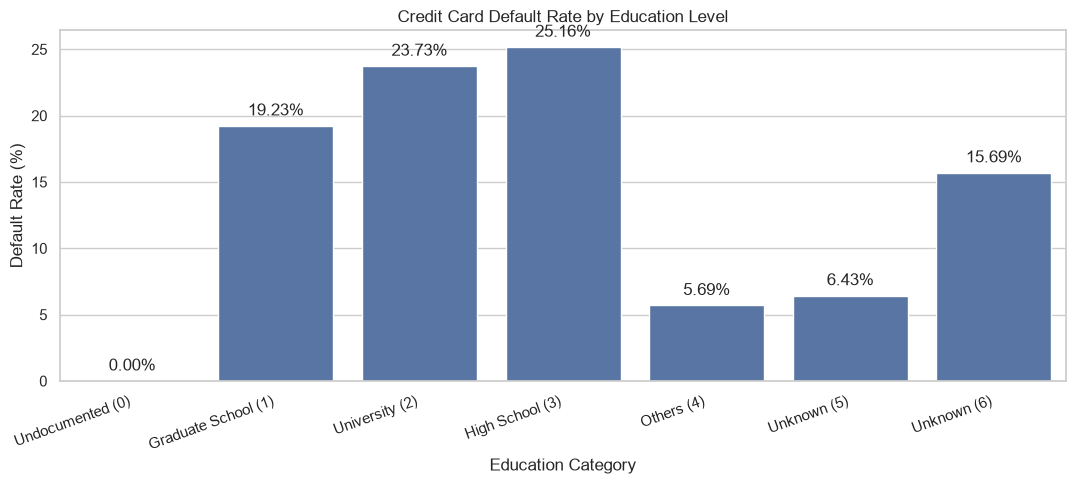

In [17]:
# Create education category labels
education_labels = {
    0: "Undocumented (0)",
    1: "Graduate School (1)",
    2: "University (2)",
    3: "High School (3)",
    4: "Others (4)",
    5: "Unknown (5)",
    6: "Unknown (6)"
}

# Prepare visualization data
education_plot = education_summary.reset_index()
education_plot["Education_Category"] = (
    education_plot["EDUCATION"].map(education_labels)
)

# Create bar chart
plt.figure(figsize=(11, 5))

ax = sns.barplot(
    data=education_plot,
    x="Education_Category",
    y="Default_Rate"
)

# Add percentage labels
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=5)

plt.title("Credit Card Default Rate by Education Level")
plt.xlabel("Education Category")
plt.ylabel("Default Rate (%)")
plt.xticks(rotation=20, ha="right")

plt.tight_layout()
plt.show()

### 2.21 Education Visualization Insights

The visualization highlights differences in credit card default rates across education categories.

Key observations:

- High School (3) has the highest default rate among the three main documented categories at 25.16%.
- University (2) follows at 23.73%.
- Graduate School (1) has the lowest rate among these categories at 19.23%.
- Categories 4, 5 and 6 have comparatively smaller sample sizes.
- The undocumented category (0) contains only 14 clients and has no recorded defaults.

The results suggest an association between education categories and default behaviour. However, smaller categories require cautious interpretation, and these observations do not establish causation.

### 2.22 Marriage Status and Credit Default Analysis

This section investigates the relationship between clients' marital status and credit card default.

The analysis will examine:

- Number of clients in each marriage category.
- Number of default and non-default clients.
- Default rate within each category.

The dataset uses the following marriage codes:

- 0: Undocumented category
- 1: Married
- 2: Single
- 3: Others

All categories will initially be analysed separately.

In [18]:
# Calculate marriage distribution by default status
marriage_default = pd.crosstab(
    df["MARRIAGE"],
    df["default payment next month"]
)

# Calculate default rates
marriage_default_rate = (
    df.groupby("MARRIAGE")["default payment next month"]
    .mean() * 100
).round(2)

# Combine results
marriage_summary = pd.DataFrame({
    "Total_Clients": df.groupby("MARRIAGE").size(),
    "Default_Clients": df.groupby("MARRIAGE")[
        "default payment next month"
    ].sum(),
    "Default_Rate": marriage_default_rate
})

print("Marriage Distribution by Default Status:")
print(marriage_default)

print("\nDefault Rate by Marriage Status:")
print(marriage_summary)

Marriage Distribution by Default Status:
default payment next month      0     1
MARRIAGE                               
0                              49     5
1                           10453  3206
2                           12623  3341
3                             239    84

Default Rate by Marriage Status:
          Total_Clients  Default_Clients  Default_Rate
MARRIAGE                                              
0                    54                5          9.26
1                 13659             3206         23.47
2                 15964             3341         20.93
3                   323               84         26.01


### 2.23 Marriage Status Analysis Findings

The relationship between marital status and credit card default was examined.

Key observations:

- The Others (3) category has the highest observed default rate of 26.01%.
- Married clients (1) have a default rate of 23.47%.
- Single clients (2) have a default rate of 20.93%.
- Single clients represent the largest category, with 15,964 observations.
- The undocumented category (0) contains only 54 observations.

The findings indicate differences in observed default rates across marital status categories.

The smaller categories should be interpreted cautiously because their sample sizes are limited. These associations do not establish causation.

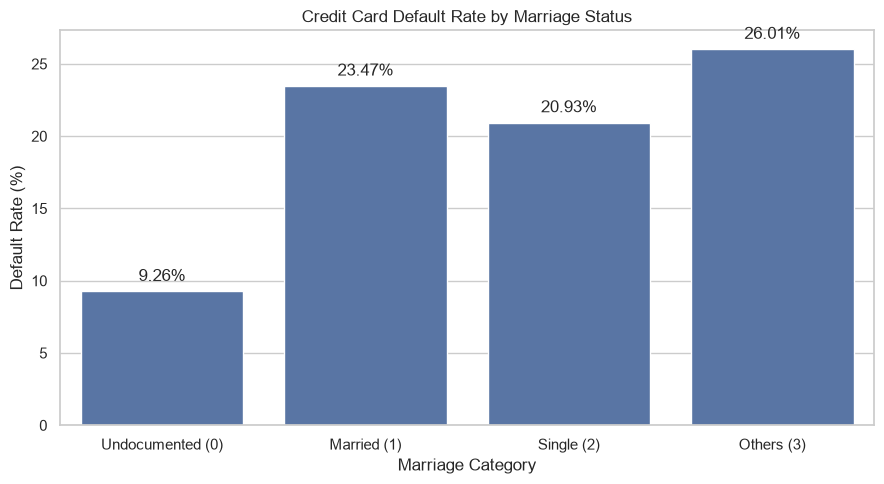

In [19]:
# Define marriage category labels
marriage_labels = {
    0: "Undocumented (0)",
    1: "Married (1)",
    2: "Single (2)",
    3: "Others (3)"
}

# Prepare visualization data
marriage_plot = marriage_summary.reset_index()
marriage_plot["Marriage_Category"] = (
    marriage_plot["MARRIAGE"].map(marriage_labels)
)

# Create bar chart
plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=marriage_plot,
    x="Marriage_Category",
    y="Default_Rate"
)

# Add percentage labels
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=5)

plt.title("Credit Card Default Rate by Marriage Status")
plt.xlabel("Marriage Category")
plt.ylabel("Default Rate (%)")

plt.tight_layout()
plt.show()

### 2.24 Marriage Status Visualization Insights

The visualization highlights differences in credit card default rates across marital status categories.

Key observations:

- Others (3) has the highest observed default rate of 26.01%.
- Married clients have a default rate of 23.47%.
- Single clients have a default rate of 20.93%.
- The undocumented category (0) has a default rate of 9.26%, but contains only 54 observations.

The results suggest differences in default behaviour across marital status categories. However, the smaller categories have limited observations and should be interpreted cautiously.

### 2.25 Repayment History and Credit Default Analysis

This section investigates the relationship between clients' previous repayment behaviour and their likelihood of defaulting in the following month.

The dataset contains six repayment status variables:

- PAY_0: September 2005
- PAY_2: August 2005
- PAY_3: July 2005
- PAY_4: June 2005
- PAY_5: May 2005
- PAY_6: April 2005

These variables represent repayment status across six historical billing periods.

The analysis will examine:

- Distribution of repayment status codes.
- Default rates across repayment status categories.
- Changes in default rates across historical repayment periods.

Repayment status codes will initially be retained in their original numerical form.

In [20]:
# Identify repayment status columns
repayment_columns = [
    "PAY_0", "PAY_2", "PAY_3",
    "PAY_4", "PAY_5", "PAY_6"
]

# Calculate frequency distributions
repayment_summary = pd.DataFrame({
    column: df[column].value_counts().sort_index()
    for column in repayment_columns
}).fillna(0).astype(int)

print("Repayment Status Distribution:")
print(repayment_summary)

Repayment Status Distribution:
    PAY_0  PAY_2  PAY_3  PAY_4  PAY_5  PAY_6
-2   2759   3782   4085   4348   4546   4895
-1   5686   6050   5938   5687   5539   5740
 0  14737  15730  15764  16455  16947  16286
 1   3688     28      4      2      0      0
 2   2667   3927   3819   3159   2626   2766
 3    322    326    240    180    178    184
 4     76     99     76     69     84     49
 5     26     25     21     35     17     13
 6     11     12     23      5      4     19
 7      9     20     27     58     58     46
 8     19      1      3      2      1      2


### 2.26 Repayment Status Distribution Findings

The frequency distributions of the six historical repayment status variables were examined.

Key observations:

- Status code 0 is the most frequent category across all six periods.
- Status codes -1 and -2 also occur frequently.
- PAY_0 contains 3,688 observations with status code 1, substantially more than the earlier repayment periods.
- Status code 2 is a frequently observed positive repayment-delay category.
- Higher positive status codes (3–8) occur comparatively infrequently.

The repayment status variables contain useful historical behavioural information.

These variables will be investigated further to determine how repayment status categories relate to subsequent credit card default.

In [21]:
# Calculate default rates for each repayment status category
repayment_default_summary = pd.DataFrame({
    column: df.groupby(column)["default payment next month"].mean() * 100
    for column in repayment_columns
}).round(2)

print("Default Rates by Repayment Status (%):")
print(repayment_default_summary)

Default Rates by Repayment Status (%):
    PAY_0  PAY_2  PAY_3  PAY_4   PAY_5   PAY_6
-2  13.23  18.27  18.53  19.25   19.69   20.04
-1  16.78  15.97  15.59  15.90   16.19   16.99
 0  12.81  15.91  17.45  18.33   18.85   18.84
 1  33.95  17.86  25.00  50.00     NaN     NaN
 2  69.14  55.61  51.56  52.33   54.19   50.65
 3  75.78  61.66  57.50  61.11   63.48   64.13
 4  68.42  50.51  57.89  66.67   60.71   63.27
 5  50.00  60.00  57.14  51.43   58.82   53.85
 6  54.55  75.00  60.87  40.00   75.00   73.68
 7  77.78  60.00  81.48  82.76   82.76   82.61
 8  57.89   0.00  66.67  50.00  100.00  100.00


### 2.26 Repayment History Analysis Findings

Default rates were calculated across all six historical repayment status variables.

Key observations:

- PAY_0 status 2 has a default rate of 69.14%.
- PAY_0 status 3 has a default rate of 75.78%.
- Repayment status categories 2 and 3 show substantially higher default rates than categories -1 and 0.
- Status code 7 has default rates above 77% across all six periods.
- Higher repayment-delay categories generally exhibit elevated default rates.
- Some categories contain very few observations, making their calculated default rates less reliable.
- NaN values indicate that a particular repayment status category has no observations in that period.

The findings suggest a strong association between historical repayment behaviour and subsequent credit card default.

Repayment history variables may provide valuable predictive information for the classification models developed in later stages.

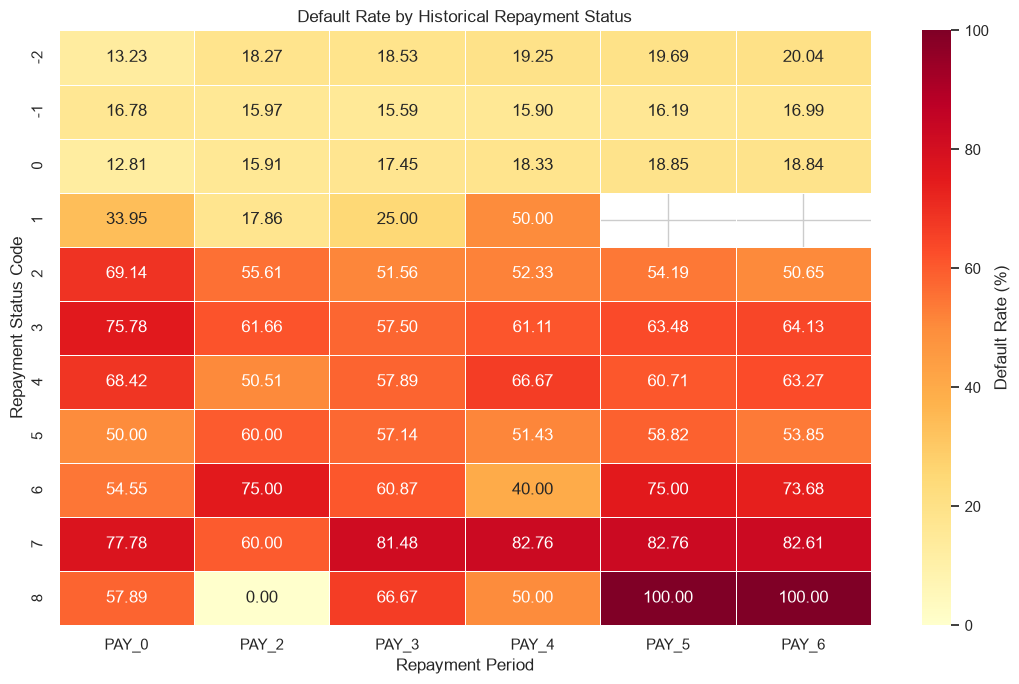

In [22]:
# Create repayment status heatmap
plt.figure(figsize=(11, 7))

sns.heatmap(
    repayment_default_summary,
    annot=True,
    fmt=".2f",
    cmap="YlOrRd",
    linewidths=0.5,
    cbar_kws={"label": "Default Rate (%)"}
)

plt.title("Default Rate by Historical Repayment Status")
plt.xlabel("Repayment Period")
plt.ylabel("Repayment Status Code")

plt.tight_layout()
plt.show()

### 2.27 Repayment History Visualization Insights

The heatmap illustrates the relationship between historical repayment status codes and subsequent credit card default rates.

Key observations:

- Repayment status codes -2, -1 and 0 generally exhibit lower default rates.
- Status code 2 shows default rates above 50% across all six repayment periods.
- Status code 3 also exhibits consistently elevated default rates.
- Status code 7 has particularly high default rates, exceeding 77% in most periods.
- Status code 8 reaches 100% in PAY_5 and PAY_6, but these percentages are based on very few observations.
- Blank cells represent repayment status categories with no observations in the corresponding period.

The visualization reinforces the association between historical repayment difficulties and subsequent credit card default.

Higher repayment-delay categories appear to contain valuable predictive information for credit risk classification.

### 2.28 Billing Amount Analysis

The dataset contains six billing amount variables:

- BILL_AMT1
- BILL_AMT2
- BILL_AMT3
- BILL_AMT4
- BILL_AMT5
- BILL_AMT6

These variables represent historical billing statement amounts across six periods.

This analysis will examine:

- Distribution of billing amounts.
- Average and median billing amounts.
- Variation across historical periods.
- Differences in billing amounts between default and non-default clients.

The objective is to understand historical billing patterns and investigate their association with credit card default.

In [23]:
# Identify billing amount columns
billing_columns = [
    "BILL_AMT1", "BILL_AMT2", "BILL_AMT3",
    "BILL_AMT4", "BILL_AMT5", "BILL_AMT6"
]

# Calculate descriptive statistics
billing_summary = df[billing_columns].describe().T

print("Billing Amount Statistics:")
print(
    billing_summary[
        ["mean", "std", "min", "25%", "50%", "75%", "max"]
    ].round(2)
)

Billing Amount Statistics:
               mean       std       min      25%      50%       75%        max
0                                                                             
BILL_AMT1  51223.33  73635.86 -165580.0  3558.75  22381.5  67091.00   964511.0
BILL_AMT2  49179.08  71173.77  -69777.0  2984.75  21200.0  64006.25   983931.0
BILL_AMT3  47013.15  69349.39 -157264.0  2666.25  20088.5  60164.75  1664089.0
BILL_AMT4  43262.95  64332.86 -170000.0  2326.75  19052.0  54506.00   891586.0
BILL_AMT5  40311.40  60797.16  -81334.0  1763.00  18104.5  50190.50   927171.0
BILL_AMT6  38871.76  59554.11 -339603.0  1256.00  17071.0  49198.25   961664.0


### 2.29 Billing Amount Analysis Findings

Descriptive statistics were calculated for all six historical billing amount variables.

Key observations:

- The average billing amount decreases from 51,223.33 in BILL_AMT1 to 38,871.76 in BILL_AMT6.
- Median billing amounts also show a declining pattern across the six periods.
- Mean values are considerably higher than median values, suggesting positively skewed distributions.
- All six variables contain negative billing values.
- BILL_AMT3 has the highest recorded billing amount of 1,664,089.
- BILL_AMT6 has the lowest recorded billing amount of -339,603.

The results indicate substantial variation in historical billing amounts.

Negative values and extreme observations will be retained for further investigation rather than removed automatically.

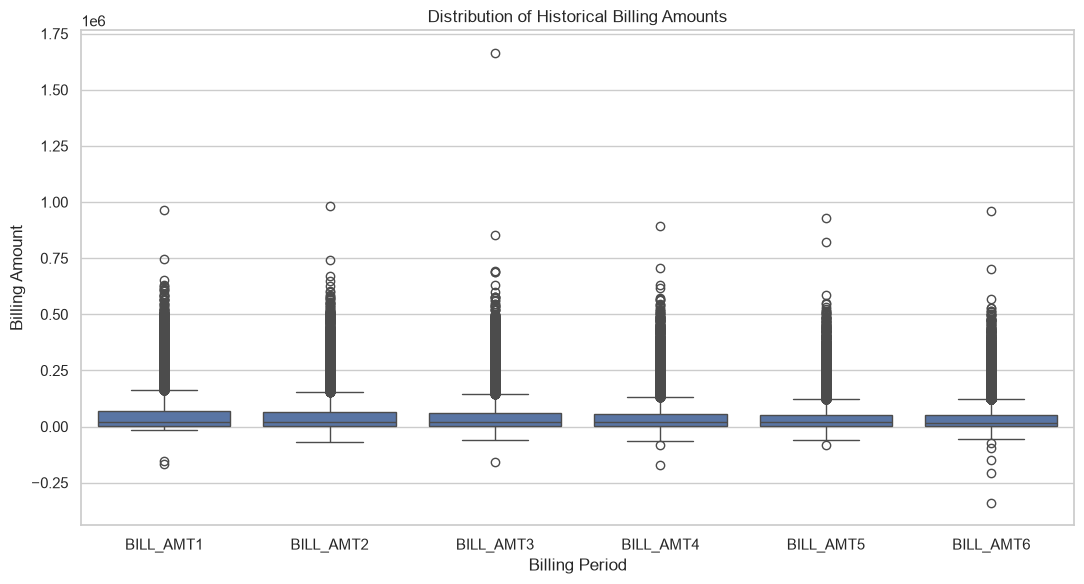

In [24]:
# Prepare billing data for visualization
billing_data = df[billing_columns].melt(
    var_name="Billing Period",
    value_name="Billing Amount"
)

# Create boxplot
plt.figure(figsize=(11, 6))

sns.boxplot(
    data=billing_data,
    x="Billing Period",
    y="Billing Amount"
)

plt.title("Distribution of Historical Billing Amounts")
plt.xlabel("Billing Period")
plt.ylabel("Billing Amount")

plt.tight_layout()
plt.show()

### 2.30 Billing Amount Visualization Insights

Boxplots were used to compare the distributions of the six historical billing amount variables.

Key observations:

- All six billing variables exhibit substantial right-skewness.
- Numerous observations extend beyond the upper whiskers, indicating potential outliers.
- BILL_AMT3 contains an especially extreme observation of approximately 1.66 million.
- Negative billing observations are present across multiple periods.
- Median values are considerably lower than the maximum recorded billing amounts.
- The interquartile ranges are relatively compressed compared with the overall data ranges.

The visualization confirms substantial variation and extreme observations in historical billing amounts.

These observations will be retained for further investigation and considered during subsequent model preprocessing.

In [25]:
# Calculate average billing amounts by default status
billing_default_summary = df.groupby(
    "default payment next month"
)[billing_columns].mean().round(2)

print("Average Billing Amount by Default Status:")
print(billing_default_summary)

Average Billing Amount by Default Status:
0                           BILL_AMT1  BILL_AMT2  BILL_AMT3  BILL_AMT4  \
default payment next month                                               
0                            51994.23   49717.44   47533.37   43611.17   
1                            48509.16   47283.62   45181.60   42036.95   

0                           BILL_AMT5  BILL_AMT6  
default payment next month                        
0                            40530.45   39042.27  
1                            39540.19   38271.44  


### 2.31 Billing Amount by Default Status Findings

Average billing amounts were compared between clients who defaulted and those who did not.

Key observations:

- Non-default clients have higher average billing amounts across all six periods.
- The largest difference occurs in BILL_AMT1.
- Average billing amounts decline across the historical periods for both groups.
- Differences between the two groups become smaller in later periods.

The findings suggest that average billing amount alone does not clearly distinguish defaulting clients from non-defaulting clients.

Historical repayment behaviour and other financial characteristics should therefore be examined alongside billing amounts.

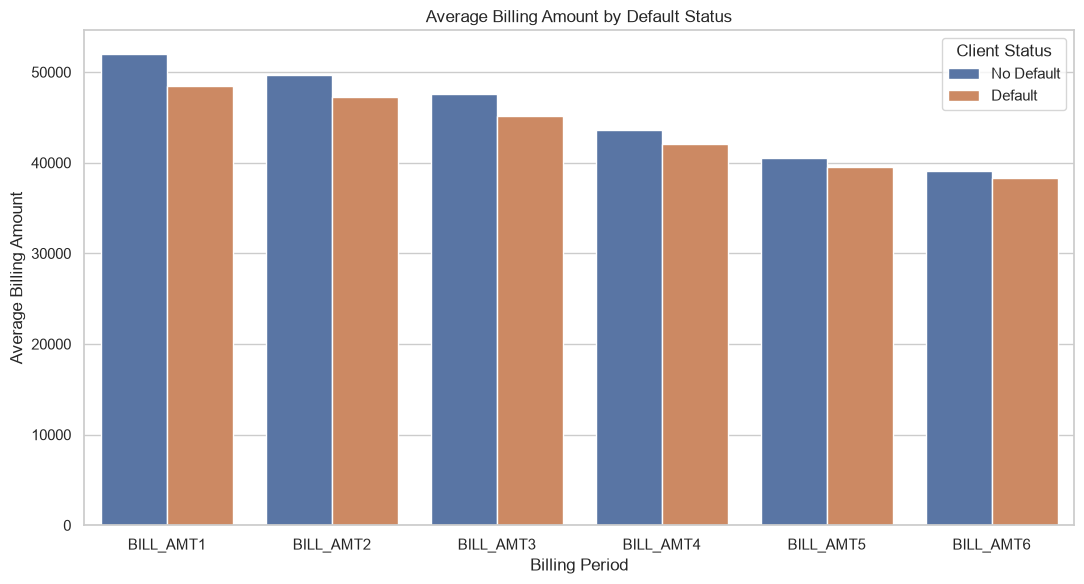

In [27]:
# Prepare billing summary for visualization
billing_plot = billing_default_summary.T.copy()

# Give the index an explicit name
billing_plot.index.name = "Billing Period"

# Convert index into a column
billing_plot = billing_plot.reset_index()

# Rename columns
billing_plot.columns = [
    "Billing Period",
    "No Default",
    "Default"
]

# Convert data into long format
billing_plot = billing_plot.melt(
    id_vars="Billing Period",
    var_name="Default Status",
    value_name="Average Billing Amount"
)

# Create grouped bar chart
plt.figure(figsize=(11, 6))

sns.barplot(
    data=billing_plot,
    x="Billing Period",
    y="Average Billing Amount",
    hue="Default Status"
)

plt.title("Average Billing Amount by Default Status")
plt.xlabel("Billing Period")
plt.ylabel("Average Billing Amount")
plt.legend(title="Client Status")

plt.tight_layout()
plt.show()

### 2.32 Billing Amount Visualization Insights

The grouped bar chart compares average historical billing amounts between default and non-default clients.

Key observations:

- Non-default clients have higher average billing amounts across all six periods.
- The largest difference appears in BILL_AMT1.
- Both groups exhibit declining average billing amounts across the six periods.
- The difference between the groups becomes smaller in later periods.
- Average billing amounts alone do not clearly separate defaulting and non-defaulting clients.

The findings suggest that billing amounts should be analysed alongside repayment history and other financial characteristics when developing credit risk prediction models.

### 2.33 Payment Amount Analysis

The dataset contains six payment amount variables:

- PAY_AMT1
- PAY_AMT2
- PAY_AMT3
- PAY_AMT4
- PAY_AMT5
- PAY_AMT6

These variables represent historical payment amounts made by clients across six billing periods.

This section examines:

- Distribution of payment amounts.
- Average and median payment amounts.
- Variation across historical periods.
- Differences in payment behaviour between default and non-default clients.

The objective is to investigate whether historical payment amounts provide useful information about subsequent credit card default.

In [31]:
# Identify payment amount columns
payment_columns = [
    "PAY_AMT1", "PAY_AMT2", "PAY_AMT3",
    "PAY_AMT4", "PAY_AMT5", "PAY_AMT6"
]

# Calculate descriptive statistics
payment_summary = df[payment_columns].describe().T

print("Payment Amount Statistics:")
print(
    payment_summary[
        ["mean", "std", "min", "25%", "50%", "75%", "max"]
    ].round(2)
)

Payment Amount Statistics:
             mean       std  min      25%     50%      75%        max
0                                                                    
PAY_AMT1  5663.58  16563.28  0.0  1000.00  2100.0  5006.00   873552.0
PAY_AMT2  5921.16  23040.87  0.0   833.00  2009.0  5000.00  1684259.0
PAY_AMT3  5225.68  17606.96  0.0   390.00  1800.0  4505.00   896040.0
PAY_AMT4  4826.08  15666.16  0.0   296.00  1500.0  4013.25   621000.0
PAY_AMT5  4799.39  15278.31  0.0   252.50  1500.0  4031.50   426529.0
PAY_AMT6  5215.50  17777.47  0.0   117.75  1500.0  4000.00   528666.0


### 2.34 Payment Amount Analysis Findings

Descriptive statistics were calculated for all six historical payment amount variables.

Key observations:

- PAY_AMT2 has the highest average payment amount of 5,921.16.
- PAY_AMT5 has the lowest average payment amount of 4,799.39.
- Median payment amounts decline from 2,100 in PAY_AMT1 to 1,500 in the later periods.
- All six variables contain zero-payment observations.
- PAY_AMT2 has the highest recorded payment amount of 1,684,259.
- Mean values are considerably higher than median values, indicating positively skewed distributions.

The findings indicate substantial variation in historical payment amounts, including zero payments and extreme high-value observations.

These variables will be further investigated to understand their relationship with credit card default.

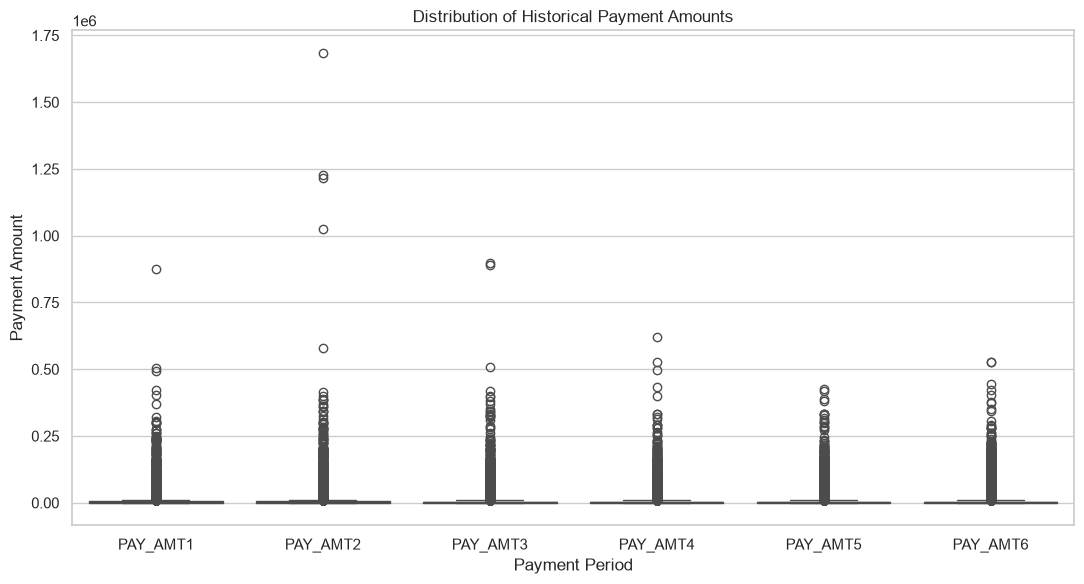

In [32]:
# Prepare payment data for visualization
payment_data = df[payment_columns].melt(
    var_name="Payment Period",
    value_name="Payment Amount"
)

# Create boxplot
plt.figure(figsize=(11, 6))

sns.boxplot(
    data=payment_data,
    x="Payment Period",
    y="Payment Amount"
)

plt.title("Distribution of Historical Payment Amounts")
plt.xlabel("Payment Period")
plt.ylabel("Payment Amount")

plt.tight_layout()
plt.show()

### 2.35 Payment Amount Visualization Insights

Boxplots were used to compare the distributions of the six historical payment amount variables.

Key observations:

- All six payment variables exhibit substantial right-skewness.
- Numerous observations extend beyond the upper whiskers, indicating potential outliers.
- PAY_AMT2 contains the highest observed payment amount of approximately 1,684,259.
- Most payment observations are concentrated near the lower end of the distributions.
- The interquartile ranges are relatively compressed compared with the overall data ranges.

The visualization indicates substantial variation in historical payment behaviour.

Extreme payment observations will be retained for further investigation rather than removed automatically.

In [33]:
# Calculate average payment amounts by default status
payment_default_summary = df.groupby(
    "default payment next month"
)[payment_columns].mean().round(2)

print("Average Payment Amount by Default Status:")
print(payment_default_summary)

Average Payment Amount by Default Status:
0                           PAY_AMT1  PAY_AMT2  PAY_AMT3  PAY_AMT4  PAY_AMT5  \
default payment next month                                                     
0                            6307.34   6640.47   5753.50   5300.53   5248.22   
1                            3397.04   3388.65   3367.35   3155.63   3219.14   

0                           PAY_AMT6  
default payment next month            
0                            5719.37  
1                            3441.48  


### 2.36 Payment Amount by Default Status Findings

Average historical payment amounts were compared between default and non-default clients.

Key observations:

- Non-default clients have higher average payment amounts across all six periods.
- The largest difference occurs in PAY_AMT2, where non-default clients average 6,640.47 compared with 3,388.65 for default clients.
- Default clients consistently show lower average payment amounts.
- Non-default clients exhibit higher payment activity across all six historical periods.

The findings suggest that historical payment amounts may provide useful information for distinguishing defaulting and non-defaulting clients.

Payment amounts should be considered alongside repayment status and billing history when developing predictive models.

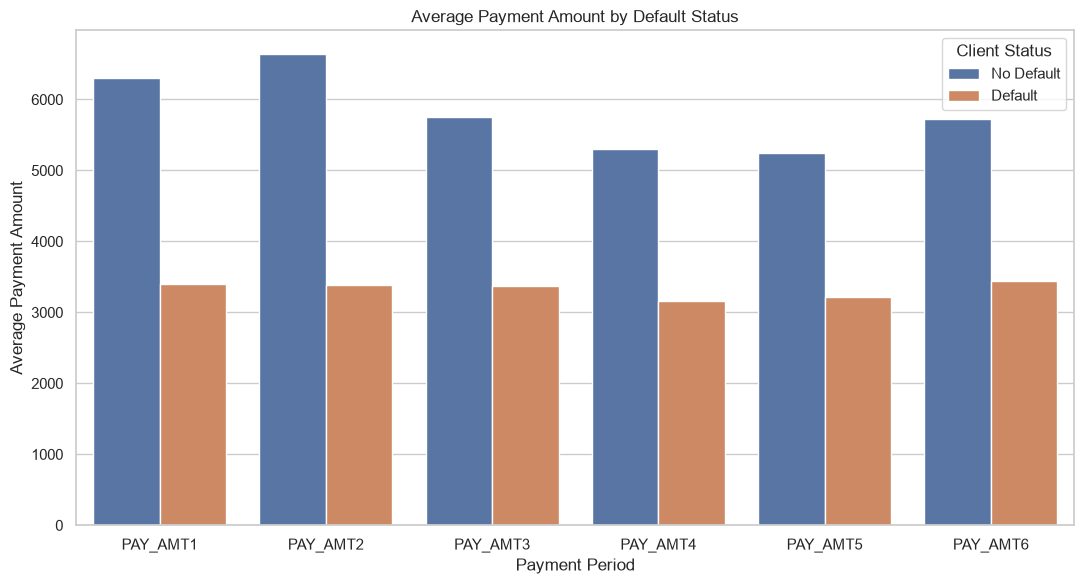

In [34]:
# Prepare payment summary for visualization
payment_plot = payment_default_summary.T.copy()

# Assign an explicit index name
payment_plot.index.name = "Payment Period"

# Convert index into a column
payment_plot = payment_plot.reset_index()

# Rename columns
payment_plot.columns = [
    "Payment Period",
    "No Default",
    "Default"
]

# Convert data into long format
payment_plot = payment_plot.melt(
    id_vars="Payment Period",
    var_name="Default Status",
    value_name="Average Payment Amount"
)

# Create grouped bar chart
plt.figure(figsize=(11, 6))

sns.barplot(
    data=payment_plot,
    x="Payment Period",
    y="Average Payment Amount",
    hue="Default Status"
)

plt.title("Average Payment Amount by Default Status")
plt.xlabel("Payment Period")
plt.ylabel("Average Payment Amount")
plt.legend(title="Client Status")

plt.tight_layout()
plt.show()

### 2.37 Payment Amount Visualization Insights

The grouped bar chart compares average historical payment amounts between default and non-default clients.

Key observations:

- Non-default clients have higher average payment amounts across all six periods.
- The largest difference appears in PAY_AMT2.
- Default clients consistently exhibit lower average payment amounts.
- The difference between the two groups remains substantial across all historical periods.
- Payment amount variables appear to provide useful information for understanding client repayment behaviour.

The visualization reinforces the association between historical payment activity and subsequent credit card default.

### 2.38 Correlation Analysis

Correlation analysis is used to examine the strength and direction of relationships between numerical variables.

This section will investigate:

- Relationships between financial variables.
- Relationships between repayment status variables.
- Correlations between predictor variables and the target variable.
- Potential multicollinearity between features.

Pearson correlation will be used to measure linear relationships.

Correlation does not establish causation, and a low Pearson correlation does not necessarily mean that a variable has no predictive value.

In [35]:
# Calculate correlation matrix
correlation_matrix = df.drop(
    columns=["ID", "AGE_GROUP", "CREDIT_LIMIT_GROUP"]
).corr()

# Display correlations with target variable
target_correlation = correlation_matrix[
    "default payment next month"
].sort_values(ascending=False)

print("Correlation with Target Variable:")
print(target_correlation.round(3))

Correlation with Target Variable:
0
default payment next month    1.000
PAY_0                         0.325
PAY_2                         0.264
PAY_3                         0.235
PAY_4                         0.217
PAY_5                         0.204
PAY_6                         0.187
EDUCATION                     0.028
AGE                           0.014
BILL_AMT6                    -0.005
BILL_AMT5                    -0.007
BILL_AMT4                    -0.010
BILL_AMT3                    -0.014
BILL_AMT2                    -0.014
BILL_AMT1                    -0.020
MARRIAGE                     -0.024
SEX                          -0.040
PAY_AMT6                     -0.053
PAY_AMT5                     -0.055
PAY_AMT3                     -0.056
PAY_AMT4                     -0.057
PAY_AMT2                     -0.059
PAY_AMT1                     -0.073
LIMIT_BAL                    -0.154
Name: default payment next month, dtype: float64


### 2.39 Correlation Analysis Findings

Pearson correlation coefficients were calculated to examine linear relationships between predictor variables and the target variable.

Key observations:

- PAY_0 has the strongest positive correlation with default at 0.325.
- PAY_2, PAY_3, PAY_4, PAY_5 and PAY_6 also show positive correlations with default.
- LIMIT_BAL has the strongest negative correlation with default at -0.154.
- Payment amount variables show weak negative correlations with default.
- Billing amounts, age, gender and education have relatively weak linear correlations with the target.

The findings indicate that historical repayment status variables have the strongest linear associations with the target variable.

Correlation does not establish causation. Furthermore, weak linear correlation does not necessarily imply that a feature lacks predictive value.

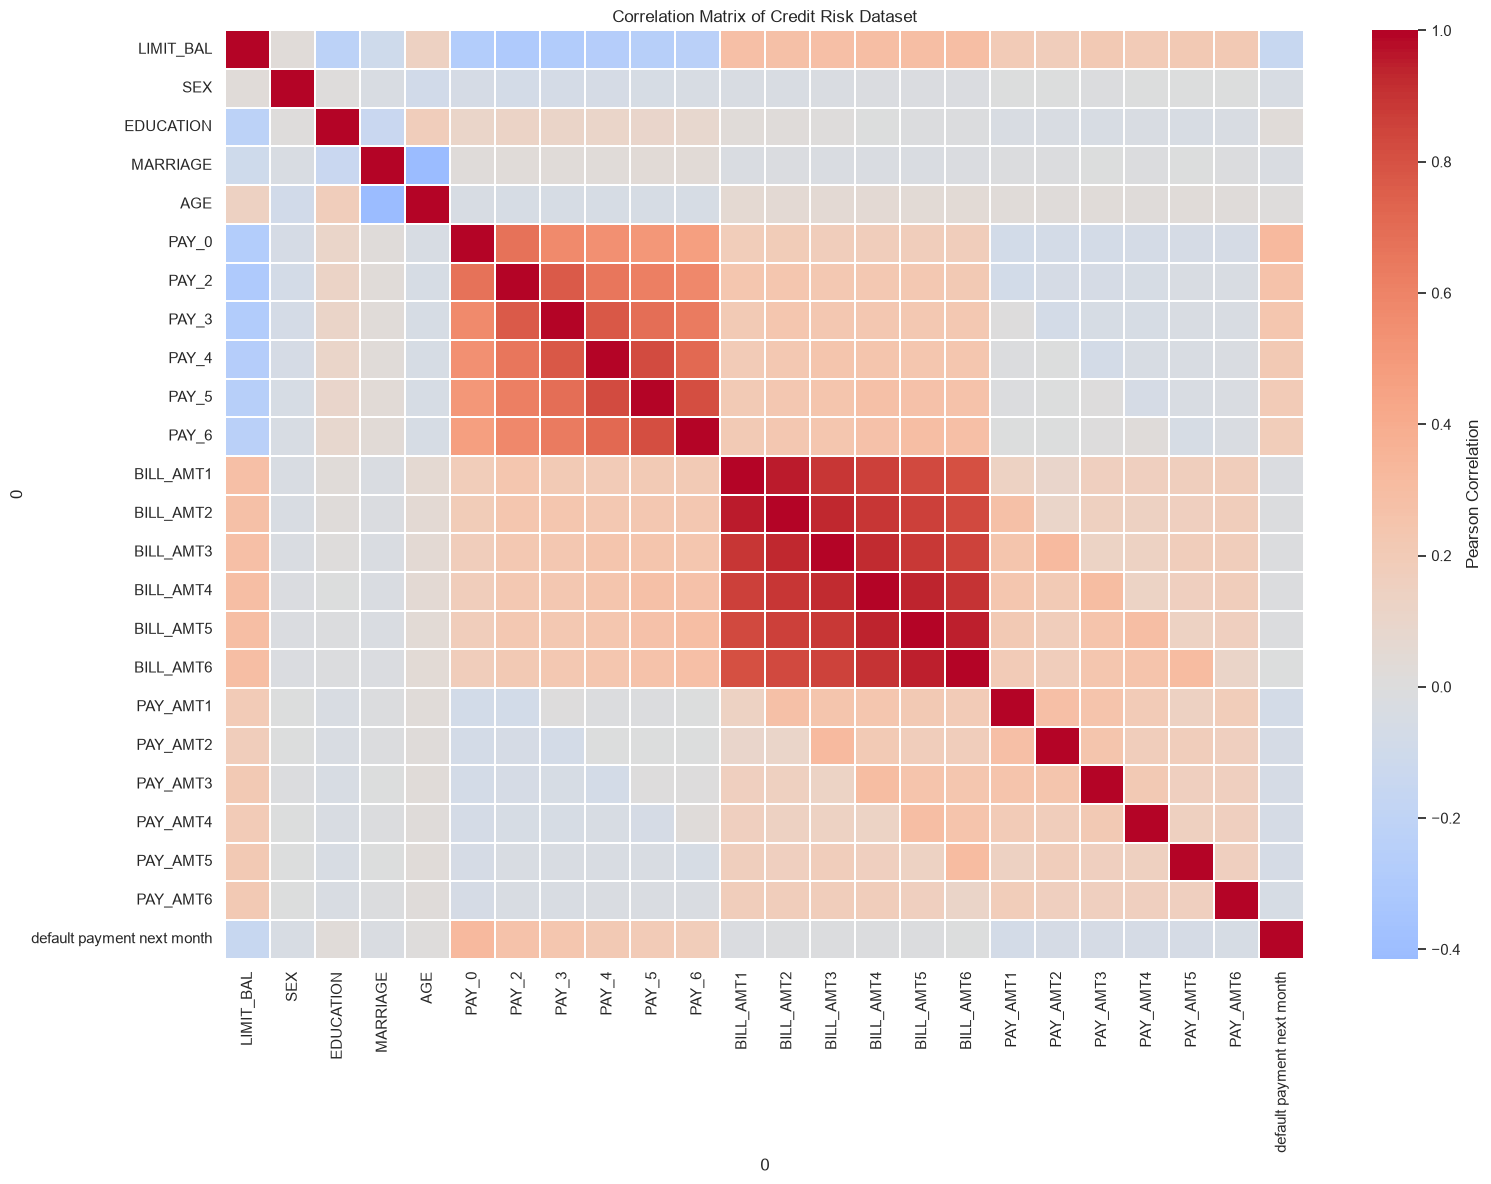

In [36]:
# Calculate correlation matrix without identifier and derived categories
correlation_matrix = df.drop(
    columns=["ID", "AGE_GROUP", "CREDIT_LIMIT_GROUP"]
).corr()

# Create correlation heatmap
plt.figure(figsize=(16, 12))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    annot=False,
    linewidths=0.3,
    cbar_kws={"label": "Pearson Correlation"}
)

plt.title("Correlation Matrix of Credit Risk Dataset")
plt.tight_layout()
plt.show()

### 2.40 Correlation Matrix Insights

The correlation heatmap was examined to identify relationships among predictor variables and potential multicollinearity.

Key observations:

- Historical repayment status variables (PAY_0 to PAY_6) exhibit positive correlations with one another.
- Billing amount variables (BILL_AMT1 to BILL_AMT6) show strong positive correlations across historical periods.
- Payment amount variables show comparatively weaker positive relationships with one another.
- LIMIT_BAL has negative correlations with repayment status variables and positive correlations with billing and payment amounts.
- Demographic variables generally exhibit weak relationships with most financial variables.

The strong correlations among historical billing and repayment variables indicate potential multicollinearity.

These relationships will be considered during feature analysis and model development. Correlated features will not be removed automatically, as they may still contain useful predictive information.

In [41]:
# Calculate absolute correlation matrix
absolute_correlation = correlation_matrix.abs()

# Create an upper-triangle mask to avoid duplicate pairs
upper_mask = np.triu(
    np.ones(absolute_correlation.shape, dtype=bool),
    k=1
)

# Identify feature pairs with correlation above 0.70
row_indices, column_indices = np.where(
    (absolute_correlation.values > 0.70) & upper_mask
)

# Create a DataFrame containing the correlated feature pairs
high_correlation_pairs = pd.DataFrame({
    "Feature 1": [
        absolute_correlation.index[i] for i in row_indices
    ],
    "Feature 2": [
        absolute_correlation.columns[j] for j in column_indices
    ],
    "Absolute Correlation": [
        absolute_correlation.iloc[i, j]
        for i, j in zip(row_indices, column_indices)
    ]
})

# Sort results by correlation strength
high_correlation_pairs = high_correlation_pairs.sort_values(
    by="Absolute Correlation",
    ascending=False
)

# Display results
print("Highly Correlated Feature Pairs (|r| > 0.70):")

if high_correlation_pairs.empty:
    print("No highly correlated feature pairs found.")
else:
    print(high_correlation_pairs.to_string(index=False))

Highly Correlated Feature Pairs (|r| > 0.70):
Feature 1 Feature 2  Absolute Correlation
BILL_AMT1 BILL_AMT2              0.951484
BILL_AMT5 BILL_AMT6              0.946197
BILL_AMT4 BILL_AMT5              0.940134
BILL_AMT2 BILL_AMT3              0.928326
BILL_AMT3 BILL_AMT4              0.923969
BILL_AMT4 BILL_AMT6              0.900941
BILL_AMT2 BILL_AMT4              0.892482
BILL_AMT1 BILL_AMT3              0.892279
BILL_AMT3 BILL_AMT5              0.883910
BILL_AMT1 BILL_AMT4              0.860272
BILL_AMT2 BILL_AMT5              0.859778
BILL_AMT3 BILL_AMT6              0.853320
BILL_AMT2 BILL_AMT6              0.831594
BILL_AMT1 BILL_AMT5              0.829779
    PAY_4     PAY_5              0.819835
    PAY_5     PAY_6              0.816900
BILL_AMT1 BILL_AMT6              0.802650
    PAY_3     PAY_4              0.777359
    PAY_2     PAY_3              0.766552
    PAY_4     PAY_6              0.716449


### 2.41 Multicollinearity Analysis Findings

Highly correlated feature pairs were identified using an absolute Pearson correlation threshold greater than 0.70.

Key observations:

- BILL_AMT1 and BILL_AMT2 have the highest observed correlation of 0.9515.
- Multiple billing amount pairs exhibit correlations above 0.90.
- PAY_4 and PAY_5 have a correlation of 0.8198.
- PAY_5 and PAY_6 have a correlation of 0.8169.
- Several consecutive repayment status variables also exhibit strong positive correlations.

These relationships indicate potential multicollinearity among historical billing and repayment variables.

Highly correlated features will not be removed automatically. Their impact will be considered during model development, particularly when interpreting Logistic Regression coefficients and comparing different model families.

## 3. Exploratory Data Analysis — Conclusion

The exploratory data analysis examined the structure, distributions and relationships within the credit card default dataset.

Major findings:

1. The dataset contains 30,000 client records and 25 columns.
2. No missing values, duplicate records or duplicate client IDs were identified.
3. The target variable is imbalanced, with 77.88% non-default and 22.12% default observations.
4. Default rates vary across demographic categories, credit limits and historical repayment behaviour.
5. Repayment status variables exhibit the strongest positive correlations with the target.
6. Defaulting clients have lower average payment amounts than non-defaulting clients across all six periods.
7. Billing amounts show substantial variation and numerous potential outliers.
8. Historical billing and repayment variables exhibit strong correlations, indicating potential multicollinearity.

The EDA suggests that historical repayment behaviour and payment activity may provide valuable predictive information.

These findings will guide the subsequent data preprocessing, feature preparation and machine learning stages.

All observations represent patterns in this dataset and should not be interpreted as evidence of causation.